#  Прогнозирование заказов такси

Компания «Чётенькое такси» собрала исторические данные о заказах такси в аэропортах. Чтобы привлекать больше водителей в период пиковой нагрузки, нужно спрогнозировать количество заказов такси на следующий час. Требуется построить модель для такого предсказания.

Значение метрики *RMSE* на тестовой выборке должно быть не больше 48.

Необходимо:

1. Загрузить данные и выполнить их ресемплирование по одному часу.
2. Проанализировать данные.
3. Обучить разные модели с различными гиперпараметрами. Сделать тестовую выборку размером 10% от исходных данных.
4. Проверить данные на тестовой выборке и сделать выводы.


Данные лежат в файле `taxi.csv`. Количество заказов находится в столбце `num_orders` (от англ. *number of orders*, «число заказов»).

## Подготовка

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import copy
from statsmodels.tsa.seasonal import seasonal_decompose

from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

from sklearn.model_selection import (train_test_split,
    GridSearchCV,
    RandomizedSearchCV,
    cross_validate,
    cross_val_score,
    TimeSeriesSplit)
from sklearn.preprocessing import (OneHotEncoder,
    OrdinalEncoder,
    StandardScaler,
    LabelEncoder)
from sklearn.compose import make_column_transformer, make_column_selector

from sklearn.metrics import fbeta_score, make_scorer
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller

import warnings
warnings.filterwarnings("ignore")

In [3]:
#Константы
RS = 42

In [4]:
#Загрузка файла данных
df = pd.read_csv('/datasets/taxi.csv', index_col='datetime', parse_dates=[0])

In [5]:
#Общая информация по датасету
df.info()
display(df.sample(10))
display(df.head())
display(df.describe().transpose())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 26496 entries, 2018-03-01 00:00:00 to 2018-08-31 23:50:00
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   num_orders  26496 non-null  int64
dtypes: int64(1)
memory usage: 414.0 KB


,num_orders
datetime,
2018-07-10 04:30:00,15
2018-03-28 13:30:00,4
2018-05-17 05:40:00,3
2018-06-01 11:40:00,23
2018-08-07 14:50:00,10
2018-05-22 04:40:00,12
2018-08-12 19:10:00,10
2018-07-01 04:50:00,23
2018-07-07 21:00:00,12


,num_orders
datetime,
2018-03-01 00:00:00,9
2018-03-01 00:10:00,14
2018-03-01 00:20:00,28
2018-03-01 00:30:00,20
2018-03-01 00:40:00,32


,count,mean,std,min,25%,50%,75%,max
num_orders,26496.0,14.070463,9.21133,0.0,8.0,13.0,19.0,119.0


In [6]:
#Пропуски
df.isna().mean()

num_orders    0.0
dtype: float64

In [7]:
#Проверка хронологического порядка дат и времени
df.index.is_monotonic

True

In [8]:
#Диапазон временного ряда данных
f"Временной ряд данных: {df.index.min()} - {df.index.max()}"

'Временной ряд данных: 2018-03-01 00:00:00 - 2018-08-31 23:50:00'

## Анализ

Выполним ресемплирование и посмотрим график

<AxesSubplot:title={'center':'orders distribution'}, xlabel='datetime', ylabel='number of orders'>

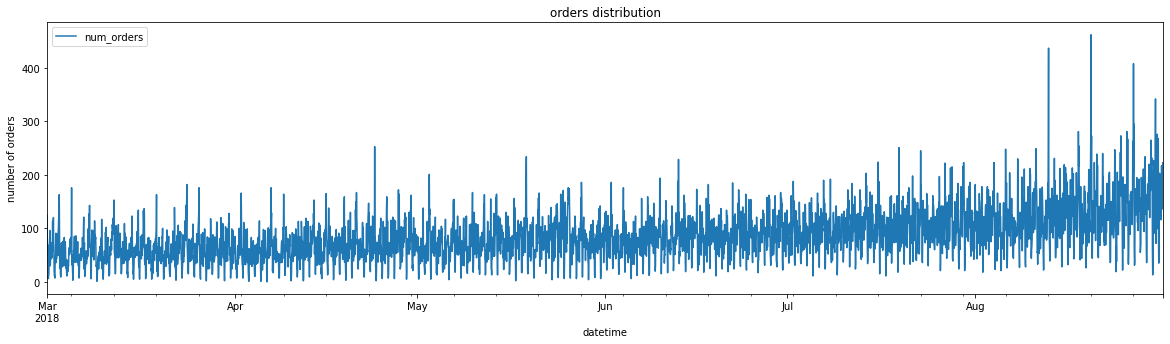

In [9]:
plt.figure(figsize=(20, 5))
df = df.resample('1H').sum()
plt.title('orders distribution')
plt.ylabel('number of orders')
df.plot(ax=plt.gca())



<div class="alert alert-block alert-danger">
<b>Ошибка:</b> Во всех графиках в проекте нужно подписать оси и названия, чтобы было понятно, что на нем визуализировано.
</div>

Разбивка временного ряда на тренд, сезонность и остаточный

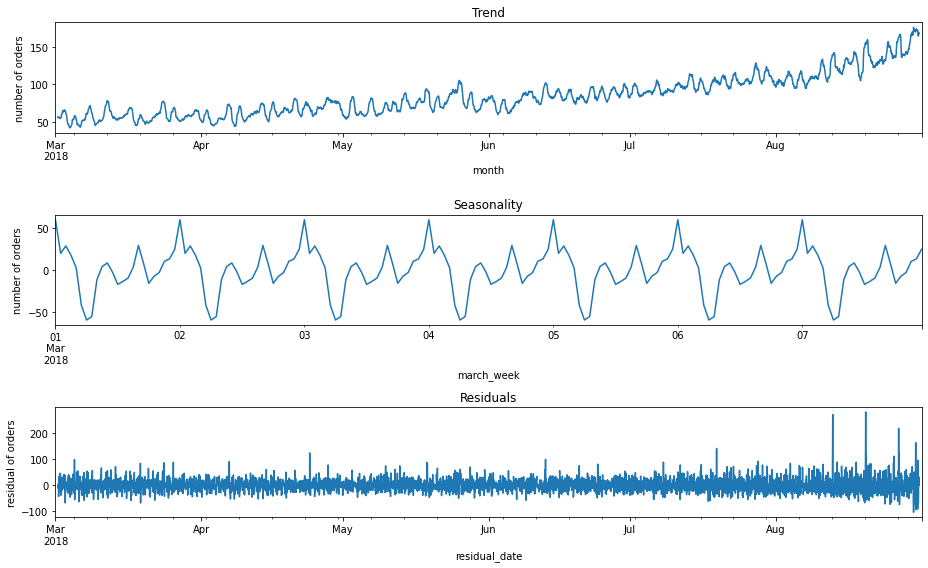

In [12]:
decomposed = seasonal_decompose(df)

plt.figure(figsize=(13, 8))
plt.subplot(311)
decomposed.trend.plot(ax=plt.gca())
plt.title('Trend')
plt.xlabel('month')
plt.ylabel('number of orders')
plt.subplot(312)
decomposed.seasonal.loc['2018-03-01':'2018-03-07'].plot(ax=plt.gca())
plt.title('Seasonality')
plt.xlabel('march_week')
plt.ylabel('number of orders')
plt.subplot(313)
decomposed.resid.plot(ax=plt.gca())
plt.title('Residuals')
plt.xlabel('residual_date')
plt.ylabel('residual of orders')
plt.tight_layout()

Посмотрим на тест Дики-Фуллера:
- Нулевая гипотеза предполагает, что временной ряд стационарный
- Альтернативная гипотеза соответственно говорит об обратном

In [10]:
adf_test = adfuller(df['num_orders'])
display('p-value = ' + str(adf_test[1]))

'p-value = 0.028940051402612906'

P-value менее 0.05 отвергаем альтернативную гипотезу, принимаем, что ряд стационарен.
Посмотрим визуально на графики и убедимся в верности гипотезы.

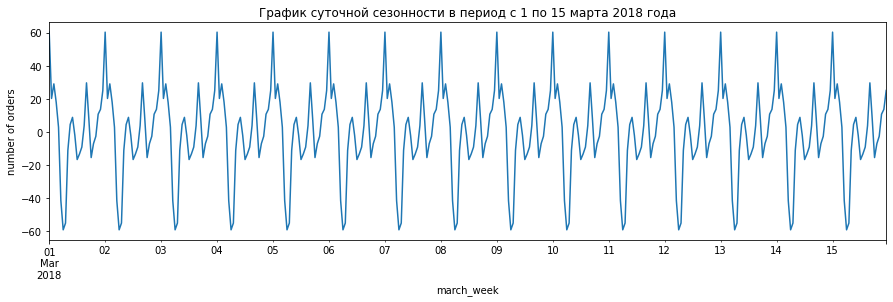

In [13]:
decomposed.seasonal['2018-03-01':'2018-03-15'].plot(figsize = (15,4), title='График суточной сезонности в период с 1 по 15 марта 2018 года')
plt.xlabel('march_week')
plt.ylabel('number of orders')
plt.show()

Вывод по графику:

- Ежедневно наблюдается наличие 3 пиков. 

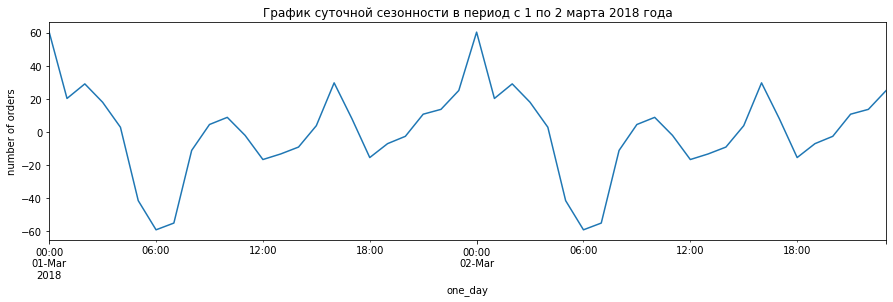

In [14]:
decomposed.seasonal['2018-03-01':'2018-03-02'].plot(figsize = (15,4), title='График суточной сезонности в период с 1 по 2 марта 2018 года')
plt.xlabel('one_day')
plt.ylabel('number of orders')
plt.show()

Выводы по графику:
  - Минимум заказов в 6 утра.
  - С 8 до 10 утра наблюдается пик.
  - Второй пик приходится на 16 часов.
  - Максимальный пик наблюдается в 24 часа.

**Выводы по данным:**

- Датасет представлен временным рядо с начала марта 2018 года до конца августа 2018 года.
- Временной ряд представлен в хронологическом порядке.
- Выполнено ресемплирование временного ряда по одному часу.
- По временному ряду видна сезонность с конца мая и конца августа, обусловленно периодами начала и окончания отпусков.
- Тренд восходящий.
- Так же определили внутридневные пики по часам
- Временной ряд стационарный.

## Обучение

Посчитаем базовый RMSE без обучения

**Добавление признаков и разбиение на выборки**

В таблице всего 1 столбец - количество заказов. Для того, чтобы обучить модели необходимо создать дополнительные признаки. Для этого напишем функцию make_features().

In [15]:
df_transform = df.copy()

In [16]:
def make_features(df, max_lag, rolling_sum_size):
    df_transform['day'] = df_transform.index.day
    df_transform['dayofweek'] = df_transform.index.dayofweek
    df_transform['hour'] = df_transform.index.hour
    for lag in range(1, max_lag + 1):
        df_transform['lag_{}'.format(lag)] = df_transform['num_orders'].shift(lag)
    df_transform['rolling_sum'] = df_transform['num_orders'].shift().rolling(rolling_sum_size).mean()
    return df_transform

In [17]:
make_features(df_transform, 47, 50)

df_transform.sample(5)

,num_orders,day,dayofweek,hour,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,...,lag_39,lag_40,lag_41,lag_42,lag_43,lag_44,lag_45,lag_46,lag_47,rolling_sum
datetime,,,,,,,,,,,,,,,,,,,,,
2018-05-04 07:00:00,13,4,4,7,29.0,17.0,16.0,52.0,74.0,54.0,...,113.0,65.0,54.0,73.0,35.0,43.0,57.0,57.0,68.0,68.54
2018-03-24 19:00:00,40,24,5,19,73.0,43.0,58.0,78.0,38.0,40.0,...,40.0,42.0,71.0,92.0,90.0,77.0,94.0,62.0,81.0,68.20
2018-04-08 23:00:00,98,8,6,23,99.0,101.0,43.0,78.0,76.0,36.0,...,63.0,18.0,17.0,37.0,20.0,78.0,67.0,67.0,129.0,57.66
2018-08-06 02:00:00,104,6,0,2,170.0,248.0,144.0,97.0,101.0,90.0,...,97.0,82.0,129.0,120.0,23.0,45.0,69.0,131.0,149.0,105.96
2018-03-12 00:00:00,102,12,0,0,118.0,89.0,119.0,99.0,99.0,107.0,...,43.0,46.0,18.0,5.0,12.0,46.0,44.0,24.0,78.0,59.96


In [18]:
df_transform = df_transform.dropna()

In [19]:
df_transform.shape

(4366, 52)

**Modeling**

In [20]:
#Разобьем данные в соответствии с заданием
X = df_transform.drop(['num_orders'], axis=1)
y = df_transform['num_orders']

X_train, X_test, y_train, y_test= train_test_split(X, y, shuffle=False, test_size=0.1)

In [21]:
tscv = TimeSeriesSplit(n_splits=5, gap=(24 * 7))

**базовая модель LinearRegression**

In [22]:
lr = LinearRegression()
scores_lr = cross_val_score(lr, X_train, y_train, cv=tscv, scoring='neg_root_mean_squared_error')
rmse_lr = -round(sum(scores_lr) / len(scores_lr), 2)
display('RMSE LinearRegression:', rmse_lr)

'RMSE LinearRegression:'

26.09

In [30]:
parametrs = {'normalize': [True, False],
            'fit_intercept': [True, False]}

gs_lr = GridSearchCV(lr, parametrs, cv=tscv, scoring= 'neg_root_mean_squared_error')
gs_lr.fit(X_train, y_train)
gs_lr.best_params_

{'fit_intercept': False, 'normalize': True}

In [31]:
gs_lr.best_score_*-1

25.92541133166627

**базовая модель RandomForestRegressor**

In [23]:
rf = RandomForestRegressor(random_state=RS)
scores_rf = cross_val_score(rf, X_train, y_train, cv=tscv, scoring='neg_root_mean_squared_error')
rmse_rf = -round(sum(scores_rf) / len(scores_rf), 2)
display('RMSE RandomForestRegressor:', rmse_rf)

'RMSE RandomForestRegressor:'

26.49

**базовая модель LGBMRegressor**

In [40]:
lgbm = LGBMRegressor() 
scores_lgbm = cross_val_score(lgbm, X_train, y_train, cv=tscv, scoring='neg_root_mean_squared_error')
rmse_lgbm = -round(sum(scores_lgbm) / len(scores_lgbm), 2)
display('RMSE LGBMRegressor:', rmse_lgbm)

'RMSE LGBMRegressor:'

26.55

**базовая модель CatBoostRegressor**

In [27]:
catboost = CatBoostRegressor(random_state=RS, learning_rate=1, logging_level='Silent')
scores_cb = cross_val_score(catboost, X_train, y_train, cv=tscv, scoring='neg_root_mean_squared_error')
rmse_cb = -round(sum(scores_cb) / len(scores_cb), 2)
print('RMSE CatBoostRegressor:', rmse_cb)

RMSE CatBoostRegressor: 32.41


In [28]:
parametrs = {'depth': range(1, 10),
            'iterations': range(1,9) }

             
#train_pool = Pool(X_train, y_train)
gs_cat = GridSearchCV(catboost, parametrs, cv=tscv, scoring= 'neg_root_mean_squared_error')
gs_cat.fit(X_train, y_train)
gs_cat.best_params_

{'depth': 3, 'iterations': 7}

In [29]:
gs_cat.best_score_*-1

28.83506304259628

In [44]:
cols = ['model', 'rmse_score']
model_data = [['LinearRegression', rmse_lr],
             ['RandomForestRegressor', rmse_rf],
             ['LGBMRegressor', rmse_lgbm],
             ['CatBoostRegressor', rmse_cb]]
model_comparison_table = pd.DataFrame(data= model_data, columns = cols)
model_comparison_table

,model,rmse_score
0,LinearRegression,26.09
1,RandomForestRegressor,26.49
2,LGBMRegressor,26.55
3,CatBoostRegressor,32.41


**Вывод:**
Лучше всего себя показала модель линейной регрессии, возьмем ее для тестирования.

<div class="alert alert-block alert-danger">
<b>Ошибка:</b> Хотя бы для одной из моделей реализуй подбор параметров.
</div>

## Тестирование

Прежде чем проверить модель на тестовой выборке, проверим качество предсказания временных рядов без обучения и сравним их результаты с результатами модели.

В качестве первого метода просто заполним предсказания медианой и посчитаем RMSE.

In [45]:
pred_median  = np.ones(y_test.shape) * y_test.median()
mean_squared_error(y_test, pred_median, squared=False)

58.983727345202425

В качестве второго метода заполним предсказания предыдущим значением ряда.

In [69]:
pred_last = y_test.shift(fill_value=y_train[-1])
mean_squared_error(y_test, pred_last, squared=False)

59.01904048345839

In [62]:
lr = LinearRegression()
lr.fit(X_train, y_train)

LinearRegression()

In [70]:
y_predicted = lr.predict(X_test)
mean_squared_error(y_test, y_predicted, squared=False)

43.256860772244174

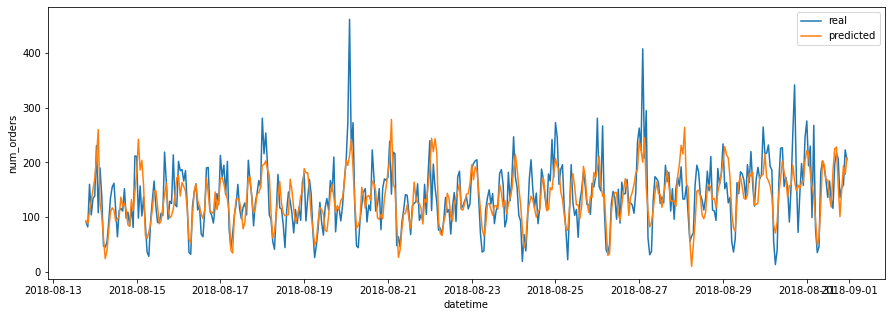

In [66]:
plt.figure(figsize=(15, 5))

sns.lineplot(x=y_test.index, y=y_test, label= 'real')
sns.lineplot(x=y_test.index, y=y_predicted, label='predicted')
plt.legend()

plt.show()

Судя по графику предсказания достаточно точны.

## Общий вывод

В этой работе:

- Загрузили данные и выполнили их ресемплирование по одному часу.

- Определили, что временной ряд является стационарным.

- Определили тренд - общее количество заказов такси увеличивается.

- Нашли часовую сезонность.

- Определили сезонность в зависимости от начала периода отпусков и окончания отпусков.

- Создали дополнительные признаки.

- Рассмотрели качество четырех моделей: линейной регрессии, случайного леса, light gradient boosting и CatBoost.

Лучше всего на обучающей выборке справилась модель линейной регрессии (26.09), хуже всего - модель catboost (32.41).

Модель линейной регрессии на тестовой выборке показывает значение метрики RMSE 43.25.


## Чек-лист проверки

- [x]  Jupyter Notebook открыт
- [ ]  Весь код выполняется без ошибок
- [ ]  Ячейки с кодом расположены в порядке исполнения
- [ ]  Данные загружены и подготовлены
- [ ]  Данные проанализированы
- [ ]  Модель обучена, гиперпараметры подобраны
- [ ]  Качество моделей проверено, выводы сделаны
- [ ]  Значение *RMSE* на тестовой выборке не больше 48